# Food Demand Analysis

This notebook answers the three questions from the supplied image, identifies the most ordered meal in every center, and explores additional demand signals using the prepared merged dataset. It does not modify the raw CSV files.

**Interpretation note:** All findings are descriptive. Differences associated with promotions, prices, center type, or operating area are not proof of causation. Week numbers have no calendar dates, so they should not be interpreted as specific seasons or holidays.

## Step 1 — Load and validate the analysis data

Question: What data coverage and quality support the analysis?

In [1]:
# Step 1: Load the prepared merged dataset without changing any source files.
# Question: What data coverage and quality support the analysis?
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

project_root = Path.cwd()
data_path = project_root / "data" / "raw" / "cleaned_merged_data.csv"
if not data_path.is_file():
    project_root = project_root.parent
    data_path = project_root / "data" / "raw" / "cleaned_merged_data.csv"
if not data_path.is_file():
    raise FileNotFoundError(f"Prepared analysis data was not found at {data_path}")

df = pd.read_csv(data_path)
required_columns = {
    "week", "center_id", "meal_id", "num_orders", "category", "cuisine",
    "center_type", "op_area", "checkout_price", "emailer_for_promotion",
    "homepage_featured",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")
if df.empty:
    raise ValueError("The prepared analysis dataset contains no rows.")

quality_summary = pd.Series({
    "rows": len(df),
    "weeks": df["week"].nunique(),
    "week range": f"{df['week'].min()}–{df['week'].max()}",
    "fulfillment centers": df["center_id"].nunique(),
    "meals": df["meal_id"].nunique(),
    "missing cells": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
})
display(quality_summary.to_frame("value"))

,value
rows,456548
weeks,145
week range,1–145
fulfillment centers,77
meals,51
missing cells,0
duplicate rows,0


## Step 2 — Weekly order demand

Question 1 from the image: How does total order demand change from one week to the next?

Average weekly orders: 824,534
Highest-demand week: 48 (1,303,457 orders)
Lowest-demand week: 62 (380,065 orders)
Largest week-over-week increase: week 48, +495,188 orders (+61.3%)
Largest week-over-week decrease: week 62, -480,040 orders (-55.8%)
Change from first to last observed week: -15.2%


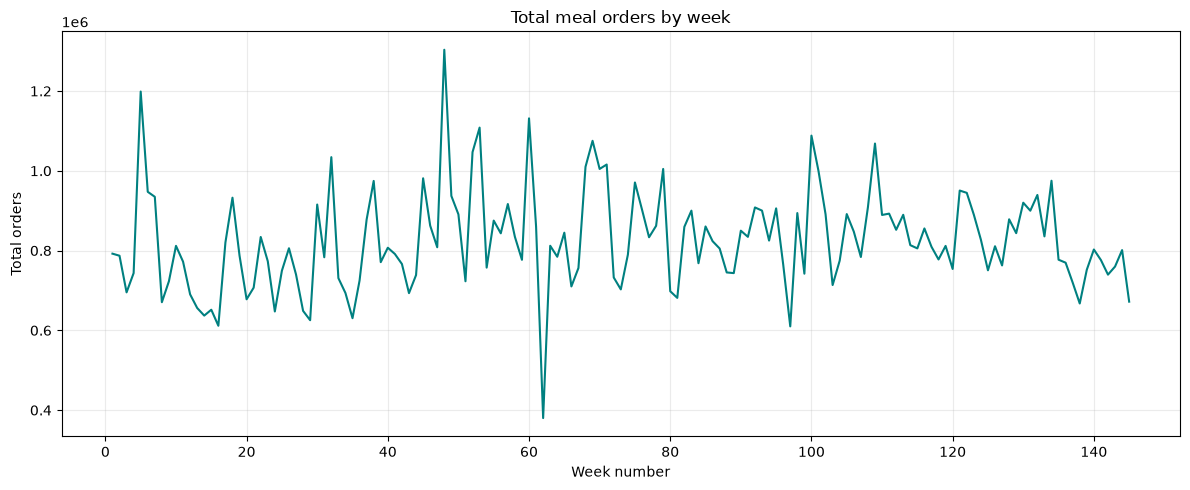

In [2]:
# Step 2: Aggregate orders by week and calculate week-over-week changes.
# Question: How does total order demand change from one week to the next?
weekly = df.groupby("week", as_index=False)["num_orders"].sum()
weekly = weekly.sort_values("week").reset_index(drop=True)
weekly["change_from_previous_week"] = weekly["num_orders"].diff()
weekly["percent_change_from_previous_week"] = weekly["num_orders"].pct_change() * 100

highest_week = weekly.loc[weekly["num_orders"].idxmax()]
lowest_week = weekly.loc[weekly["num_orders"].idxmin()]
largest_increase = weekly.loc[weekly["change_from_previous_week"].idxmax()]
largest_decrease = weekly.loc[weekly["change_from_previous_week"].idxmin()]
first_to_last_percent = (weekly["num_orders"].iloc[-1] / weekly["num_orders"].iloc[0] - 1) * 100

print(f"Average weekly orders: {weekly['num_orders'].mean():,.0f}")
print(f"Highest-demand week: {int(highest_week['week'])} ({int(highest_week['num_orders']):,} orders)")
print(f"Lowest-demand week: {int(lowest_week['week'])} ({int(lowest_week['num_orders']):,} orders)")
print(
    f"Largest week-over-week increase: week {int(largest_increase['week'])}, "
    f"{int(largest_increase['change_from_previous_week']):+,} orders "
    f"({largest_increase['percent_change_from_previous_week']:+.1f}%)"
)
print(
    f"Largest week-over-week decrease: week {int(largest_decrease['week'])}, "
    f"{int(largest_decrease['change_from_previous_week']):+,} orders "
    f"({largest_decrease['percent_change_from_previous_week']:+.1f}%)"
)
print(f"Change from first to last observed week: {first_to_last_percent:+.1f}%")

# Plot totals so the overall volatility and abrupt changes are visible.
ax = weekly.plot(x="week", y="num_orders", figsize=(12, 5), legend=False, color="teal")
ax.set(title="Total meal orders by week", xlabel="Week number", ylabel="Total orders")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Step 3 — Categories, meals, and cuisines

Question 2 from the image: Which meal categories and meals account for most orders? Which cuisines lead?

In [3]:
# Step 3: Rank categories, individual meals, and cuisines by total orders.
# Question: Which categories and meals account for most orders, and which cuisines lead?
total_orders = df["num_orders"].sum()
category_orders = (
    df.groupby("category")["num_orders"].sum()
    .sort_values(ascending=False)
    .rename("orders")
    .to_frame()
)
category_orders["share_percent"] = category_orders["orders"] / total_orders * 100

meal_orders = (
    df.groupby(["meal_id", "category", "cuisine"], as_index=False)["num_orders"]
    .sum()
    .sort_values("num_orders", ascending=False)
)
meal_orders["share_percent"] = meal_orders["num_orders"] / total_orders * 100
cuisine_orders = (
    df.groupby("cuisine")["num_orders"].sum()
    .sort_values(ascending=False)
    .rename("orders")
    .to_frame()
)
cuisine_orders["share_percent"] = cuisine_orders["orders"] / total_orders * 100

print("Orders by category (largest first):")
display(category_orders.round({"share_percent": 2}))
print("Top 10 individual meals across all centers and weeks:")
display(meal_orders.head(10).round({"share_percent": 2}))
print("Orders by cuisine:")
display(cuisine_orders.round({"share_percent": 2}))
top_three_category_share = category_orders["share_percent"].head(3).sum()
print(f"The three largest categories account for {top_three_category_share:.2f}% of all orders.")

Orders by category (largest first):


,orders,share_percent
category,,
Beverages,40480525,33.86
Rice Bowl,20874063,17.46
Sandwich,17636782,14.75
Salad,10944336,9.15
Pizza,7383720,6.18
Other Snacks,4766293,3.99
Starters,4649122,3.89
Extras,3984979,3.33
Seafood,2715714,2.27


Top 10 individual meals across all centers and weeks:


,meal_id,category,cuisine,num_orders,share_percent
30,2290,Rice Bowl,Indian,9770303,8.17
22,1885,Beverages,Thai,8346246,6.98
16,1754,Sandwich,Italian,6818059,5.70
26,1993,Beverages,Thai,6656856,5.57
1,1109,Rice Bowl,Indian,6367773,5.33
46,2707,Beverages,Italian,5932792,4.96
25,1971,Sandwich,Italian,5728620,4.79
48,2826,Sandwich,Italian,5090103,4.26
15,1727,Rice Bowl,Indian,4735987,3.96
0,1062,Beverages,Italian,4712795,3.94


Orders by cuisine:


,orders,share_percent
cuisine,,
Italian,44172832,36.95
Thai,32677670,27.33
Indian,25792544,21.57
Continental,16914439,14.15


The three largest categories account for 66.07% of all orders.


## Step 4 — Center performance and center type

Question 3 from the image: Which centers have the highest order volume, and does observed performance differ by center type?

Total orders are useful for workload, but center types have different numbers of centers. The per-center averages and per-observation order levels help make the comparison fairer.

In [4]:
# Step 4: Rank centers and compare center types using both totals and normalized summaries.
# Question: Which centers have the highest order volume, and does performance differ by center type?
center_summary = (
    df.groupby("center_id")
    .agg(
        total_orders=("num_orders", "sum"),
        mean_orders_per_meal_week=("num_orders", "mean"),
        center_type=("center_type", "first"),
        op_area=("op_area", "first"),
    )
    .sort_values("total_orders", ascending=False)
)
type_summary = (
    df.groupby("center_type")
    .agg(
        total_orders=("num_orders", "sum"),
        mean_orders_per_meal_week=("num_orders", "mean"),
        median_orders_per_meal_week=("num_orders", "median"),
        center_count=("center_id", "nunique"),
    )
)
type_per_center = (
    center_summary.reset_index()
    .groupby("center_type")["total_orders"]
    .agg(mean_orders_per_center="mean", median_orders_per_center="median")
)
type_summary = type_summary.join(type_per_center).sort_values(
    "mean_orders_per_center", ascending=False
)

print("Top 10 centers by total orders (over all observed weeks):")
display(center_summary.head(10).round(2))
print("Center-type comparison; total orders reflect the number of centers in each type:")
display(type_summary.round(2))

Top 10 centers by total orders (over all observed weeks):


,total_orders,mean_orders_per_meal_week,center_type,op_area
center_id,,,,
13,4296545,609.78,TYPE_B,6.7
43,3920294,562.45,TYPE_A,5.1
10,3381018,481.97,TYPE_B,6.3
52,3125835,446.99,TYPE_B,5.6
137,3117478,452.20,TYPE_A,4.4
67,2839493,410.63,TYPE_B,7.0
11,2797300,411.31,TYPE_A,3.7
174,2792587,405.25,TYPE_A,7.0
104,2427542,363.02,TYPE_A,4.5


Center-type comparison; total orders reflect the number of centers in each type:


,total_orders,mean_orders_per_meal_week,median_orders_per_meal_week,center_count,mean_orders_per_center,median_orders_per_center
center_type,,,,,,
TYPE_B,29996073,318.86,176.0,15,1999738.20,1906535.0
TYPE_A,68978517,262.39,136.0,43,1604151.56,1451046.0
TYPE_C,20582895,206.67,107.0,19,1083310.26,1015920.0


## Step 5 — Most ordered meal in every center

Question: What is the most ordered meal within each center across all observed weeks? Ties are retained.

In [5]:
# Step 5: Find the meal with the largest cumulative order count separately in each center.
# Question: What is the most ordered meal within each center across all observed weeks?
center_meal_orders = (
    df.groupby(["center_id", "meal_id", "category", "cuisine"], as_index=False)["num_orders"]
    .sum()
)
center_meal_orders["center_max_orders"] = center_meal_orders.groupby("center_id")["num_orders"].transform("max")
top_meal_by_center = (
    center_meal_orders.loc[
        center_meal_orders["num_orders"].eq(center_meal_orders["center_max_orders"])
    ]
    .drop(columns="center_max_orders")
    .sort_values(["center_id", "num_orders"], ascending=[True, False])
    .reset_index(drop=True)
)
print(f"Most-ordered meal(s) found for {top_meal_by_center['center_id'].nunique()} centers; tied meals are included.")
display(top_meal_by_center)
print("Meals most frequently ranked first across centers:")
top_meal_frequency = (
    top_meal_by_center.groupby(["meal_id", "category", "cuisine"])["center_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("number_of_centers")
    .to_frame()
)
display(top_meal_frequency.head(10))

Most-ordered meal(s) found for 77 centers; tied meals are included.


,center_id,meal_id,category,cuisine,num_orders
0,10,2290,Rice Bowl,Indian,276984
1,11,1885,Beverages,Thai,219447
2,13,1885,Beverages,Thai,334334
3,14,1885,Beverages,Thai,93530
4,17,1885,Beverages,Thai,89419
...,...,...,...,...,...
72,161,2290,Rice Bowl,Indian,78989
73,162,1754,Sandwich,Italian,89022
74,174,1885,Beverages,Thai,310876
75,177,2290,Rice Bowl,Indian,82750


Meals most frequently ranked first across centers:


,,,number_of_centers
meal_id,category,cuisine,
2290,Rice Bowl,Indian,39
1885,Beverages,Thai,23
1754,Sandwich,Italian,10
2707,Beverages,Italian,2
1727,Rice Bowl,Indian,1
2490,Salad,Italian,1
2826,Sandwich,Italian,1


## Step 6 — Promotional exposure and order volume

Additional question: Are email promotion and homepage featuring associated with different observed order counts?

In [6]:
# Step 6: Compare order counts for promoted versus non-promoted observations.
# Question: Are email promotion and homepage featuring associated with different observed order counts?
promotion_summaries = []
for flag, label in [
    ("emailer_for_promotion", "Email promotion"),
    ("homepage_featured", "Homepage featured"),
]:
    summary = df.groupby(flag)["num_orders"].agg(
        observations="size", mean_orders="mean", median_orders="median", total_orders="sum"
    )
    summary = summary.rename(index={0: "No", 1: "Yes"}).reset_index(names="exposure")
    summary.insert(0, "promotion_type", label)
    promotion_summaries.append(summary)
promotion_comparison = pd.concat(promotion_summaries, ignore_index=True)
display(promotion_comparison.round(2))
print("These are unadjusted associations; promotion placement and meal popularity may differ.")

,promotion_type,exposure,observations,mean_orders,median_orders,total_orders
0,Email promotion,No,419498,229.26,123.0,96175321
1,Email promotion,Yes,37050,631.10,338.0,23382164
2,Homepage featured,No,406693,221.05,123.0,89899504
3,Homepage featured,Yes,49855,594.88,350.0,29657981


These are unadjusted associations; promotion placement and meal popularity may differ.


## Step 7 — Price and center operating area

Additional questions: How do observed order counts vary across checkout-price bands? Are larger operating areas associated with higher center totals?

In [7]:
# Step 7: Describe demand across checkout-price quartiles and relate center totals to operating area.
# Question: How do order counts vary by checkout-price band, and is operating area associated with center demand?
price_data = df[["checkout_price", "num_orders"]].copy()
price_data["checkout_price_quartile"] = pd.qcut(
    price_data["checkout_price"], q=4, duplicates="drop"
)
price_summary = price_data.groupby("checkout_price_quartile", observed=True)["num_orders"].agg(
    observations="size", mean_orders="mean", median_orders="median", total_orders="sum"
)
print("Observed orders by checkout-price quartile:")
display(price_summary.round(2))

center_area_relationship = center_summary[["total_orders", "op_area"]].corr(method="pearson").loc[
    "total_orders", "op_area"
]
print(
    "Pearson correlation between center total orders and operating area "
    f"(one observation per center): {center_area_relationship:.3f}"
)
print("Price bands and operating-area correlation are descriptive and do not establish causal effects.")

Observed orders by checkout-price quartile:


,observations,mean_orders,median_orders,total_orders
checkout_price_quartile,,,,
"(2.9690000000000003, 228.95]",114191,427.01,256.0,48760994
"(228.95, 296.82]",114513,293.31,163.0,33588022
"(296.82, 445.23]",118733,210.89,136.0,25040054
"(445.23, 866.27]",109111,111.52,67.0,12168415


Pearson correlation between center total orders and operating area (one observation per center): 0.728
Price bands and operating-area correlation are descriptive and do not establish causal effects.


## Questions answered in this notebook

1. **How does total order demand change from one week to the next?** — Demand is volatile: week 48 is highest (1,303,457 orders) and week 62 lowest (380,065); the largest weekly rise is 495,188 orders (+61.3%) and the largest fall is 480,040 (-55.8%). Week 145 is 15.2% below week 1.
2. **Which meal categories and meals account for most orders?** — Beverages lead categories (33.86%), followed by Rice Bowl (17.46%) and Sandwich (14.75%). Meal 2290 (Indian Rice Bowl) leads individual meals with 9,770,303 orders (8.17%); the three largest categories make up 66.07%.
3. **Which centers have the highest order volume, and does observed performance differ by center type?** — Center 13 leads total orders (4,296,545). TYPE_B has the highest average total per center (1,999,738 across 15 centers) and the highest mean per center-meal-week observation (318.86 orders); raw type totals are affected by different center counts.
4. **What is the most ordered meal within each center?** — The table in Step 5 gives the winning meal for all 77 centers. Meal 2290 leads in 39 centers, meal 1885 in 23, and meal 1754 in 10; ties, if any, are included.
5. **Which cuisines account for the most orders?** — Italian leads (36.95%), followed by Thai (27.33%), Indian (21.57%), and Continental (14.15%).
6. **Are email promotion and homepage featuring associated with different observed order counts?** — Yes, unadjusted means are higher for promoted observations: email 631.10 versus 229.26 without email; homepage-featured 594.88 versus 221.05 without featuring.
7. **How do observed order counts vary across checkout-price bands?** — Average orders decline from 427.01 in the lowest checkout-price quartile to 111.52 in the highest quartile.
8. **Are larger operating areas associated with higher center order totals?** — The center-level Pearson correlation is positive (r = 0.728); this is an association, not a causal result.

The promotion and price comparisons are unadjusted; these data do not establish that either exposure or price caused a change in orders. The center-type total also reflects different numbers of centers in each type.

In [8]:
# Step 8: Calculate the requested demand, sales, discount, promotion, and meal-volatility indicators.
# Question: What are total and average weekly orders, estimated sales, average discount,
# the order share exposed to promotions, and demand volatility for each meal?

# Step 8.1: Check that the existing analysis dataframe contains all required columns.
indicator_columns = {
    "week", "meal_id", "num_orders", "checkout_price", "base_price",
    "emailer_for_promotion", "homepage_featured",
}
missing_indicator_columns = indicator_columns.difference(df.columns)
if missing_indicator_columns:
    raise ValueError(f"Missing columns for indicators: {sorted(missing_indicator_columns)}")
if df.empty:
    raise ValueError("Cannot calculate indicators from an empty dataframe.")

# Step 8.2: Use a working copy; estimate sales as ordered units multiplied by checkout price.
# This is sales value, not profit or net revenue.
indicators_data = df.copy()
indicators_data["estimated_sales"] = (
    indicators_data["num_orders"] * indicators_data["checkout_price"]
)

# Step 8.3: Calculate the discount rate from base and checkout prices.
# Negative rates are kept because a checkout price may exceed the base price.
if indicators_data["base_price"].eq(0).any():
    raise ValueError("Discount rate cannot be calculated when a base price is zero.")
indicators_data["discount_rate"] = (
    indicators_data["base_price"] - indicators_data["checkout_price"]
) / indicators_data["base_price"]

# Step 8.4: Count an observation as promoted if either promotion flag is set.
# Calculate the order-weighted promoted share so one observation with both flags is not double-counted.
indicators_data["has_any_promotion"] = (
    indicators_data["emailer_for_promotion"].eq(1)
    | indicators_data["homepage_featured"].eq(1)
)
total_orders = indicators_data["num_orders"].sum()
if total_orders == 0:
    raise ValueError("Promotion order share cannot be calculated when total orders equal zero.")
orders_with_promotion = indicators_data.loc[
    indicators_data["has_any_promotion"], "num_orders"
].sum()

# Step 8.5: Aggregate orders by week to calculate total demand and average weekly demand.
weekly_orders = indicators_data.groupby("week")["num_orders"].sum().sort_index()
if weekly_orders.empty:
    raise ValueError("No weekly order totals are available for the indicators.")

# Step 8.6: Calculate both the row-average discount from the image's formula and an order-weighted average.
average_discount_rate = indicators_data["discount_rate"].mean()
order_weighted_discount_rate = (
    indicators_data["discount_rate"] * indicators_data["num_orders"]
).sum() / total_orders

# Step 8.7: Aggregate each meal's demand across centers by week, then calculate std / mean.
meal_weekly_orders = indicators_data.groupby(["meal_id", "week"])["num_orders"].sum()
meal_volatility = (
    meal_weekly_orders.groupby(level="meal_id")
    .agg(mean_weekly_orders="mean", std_weekly_orders="std")
    .reset_index()
)
meal_volatility["demand_volatility_cv"] = (
    meal_volatility["std_weekly_orders"] / meal_volatility["mean_weekly_orders"]
)
meal_volatility = meal_volatility.sort_values(
    "demand_volatility_cv", ascending=False, na_position="last"
).reset_index(drop=True)

# Step 8.8: Show the overall indicators and the volatility measure for every meal.
indicator_summary = pd.Series({
    "total_orders": total_orders,
    "average_orders_per_week": weekly_orders.mean(),
    "standard_deviation_of_weekly_orders": weekly_orders.std(),
    "estimated_sales_at_checkout_price": indicators_data["estimated_sales"].sum(),
    "average_discount_rate_percent": average_discount_rate * 100,
    "order_weighted_discount_rate_percent": order_weighted_discount_rate * 100,
    "orders_with_any_promotion": orders_with_promotion,
    "share_of_orders_with_any_promotion_percent": orders_with_promotion / total_orders * 100,
})
print("Overall indicators:")
display(indicator_summary.to_frame("value").round(2))
print("Weekly meal demand volatility (coefficient of variation = standard deviation / mean):")
display(meal_volatility.round(3))

Overall indicators:


,value
total_orders,1.195575e+08
average_orders_per_week,8.245344e+05
standard_deviation_of_weekly_orders,1.256703e+05
estimated_sales_at_checkout_price,3.192277e+10
average_discount_rate_percent,5.720000e+00
order_weighted_discount_rate_percent,9.240000e+00
orders_with_any_promotion,3.734292e+07
share_of_orders_with_any_promotion_percent,3.123000e+01


Weekly meal demand volatility (coefficient of variation = standard deviation / mean):


,meal_id,mean_weekly_orders,std_weekly_orders,demand_volatility_cv
0,2444,6500.469,7833.130,1.205
1,1971,39507.724,43605.509,1.104
2,1445,7304.972,7986.194,1.093
3,2867,4923.621,4953.653,1.006
4,2490,29673.000,27959.324,0.942
5,2290,67381.400,60641.916,0.900
6,1754,47021.097,41698.021,0.887
7,2104,1838.586,1513.660,0.823
8,1727,32661.979,26274.639,0.804
9,1558,12061.655,9383.111,0.778


In [9]:
# Step 9: Compare promoted and unpromoted orders within each center-meal pair.
# Question: For the same meal in the same center, do order distributions differ with promotion?
# Report the median difference as a percentage of the unpromoted median.

# Step 9.1: Import the statistical test and validate the columns and promotion flags.
from scipy.stats import mannwhitneyu

promotion_columns = ["emailer_for_promotion", "homepage_featured"]
required_test_columns = {"center_id", "meal_id", "num_orders", *promotion_columns}
missing_test_columns = required_test_columns.difference(df.columns)
if missing_test_columns:
    raise ValueError(f"Missing columns for promotion tests: {sorted(missing_test_columns)}")

# Step 9.2: Run a separate two-sided Mann-Whitney test for each promotion indicator.
# Tests are run only in center-meal pairs that have observations both with and without that promotion.
test_rows = []
exclusion_rows = []
alpha = 0.05

for promotion_column in promotion_columns:
    relevant = df[["center_id", "meal_id", "num_orders", promotion_column]].copy()
    missing_mask = relevant[["num_orders", promotion_column]].isna().any(axis=1)
    missing_rows = int(missing_mask.sum())
    relevant = relevant.loc[~missing_mask].copy()

    # Step 9.3: Reject unexpected flag values instead of silently treating them as 0 or 1.
    unexpected_mask = ~relevant[promotion_column].isin([0, 1])
    unexpected_values = sorted(relevant.loc[unexpected_mask, promotion_column].unique().tolist())
    if unexpected_values:
        raise ValueError(
            f"Unexpected values for {promotion_column}: {unexpected_values}; expected only 0 and 1."
        )

    # Step 9.4: Keep only center-meal pairs with both groups, ensuring comparisons share center and meal.
    group_sizes = relevant.groupby(["center_id", "meal_id", promotion_column]).size().unstack(fill_value=0)
    for flag_value in [0, 1]:
        if flag_value not in group_sizes.columns:
            group_sizes[flag_value] = 0
    matched_index = group_sizes.index[(group_sizes[0] > 0) & (group_sizes[1] > 0)]
    pair_index = pd.MultiIndex.from_frame(relevant[["center_id", "meal_id"]])
    matched = relevant.loc[pair_index.isin(matched_index)]
    unmatched_rows = len(relevant) - len(matched)
    exclusion_rows.append({
        "promotion_type": promotion_column,
        "missing_rows_excluded": missing_rows,
        "rows_excluded_without_both_groups": unmatched_rows,
        "unexpected_values": unexpected_values,
    })

    # Step 9.5: Test each matched pair and calculate the median percent difference.
    for (center_id, meal_id), pair in matched.groupby(["center_id", "meal_id"]):
        orders_without = pair.loc[pair[promotion_column].eq(0), "num_orders"]
        orders_with = pair.loc[pair[promotion_column].eq(1), "num_orders"]
        median_without = orders_without.median()
        median_with = orders_with.median()
        percent_difference = (
            (median_with - median_without) / median_without * 100
            if median_without != 0 else float("nan")
        )
        test_result = mannwhitneyu(
            orders_with,
            orders_without,
            alternative="two-sided",
            method="asymptotic",
            use_continuity=True,
        )
        test_rows.append({
            "promotion_type": promotion_column,
            "center_id": center_id,
            "meal_id": meal_id,
            "n_without": len(orders_without),
            "n_with": len(orders_with),
            "median_without": median_without,
            "median_with": median_with,
            "median_difference_percent": percent_difference,
            "u_statistic": test_result.statistic,
            "p_value": test_result.pvalue,
        })

# Step 9.6: Adjust p-values for the many center-meal tests with Benjamini-Hochberg FDR, per indicator.
mann_whitney_results = pd.DataFrame(test_rows)
if mann_whitney_results.empty:
    raise ValueError("No center-meal pairs had observations in both promotion groups.")
mann_whitney_results["p_value_bh"] = float("nan")
for promotion_column, result_index in mann_whitney_results.groupby("promotion_type").groups.items():
    p_values = mann_whitney_results.loc[result_index, "p_value"].to_numpy()
    order = p_values.argsort()
    ranked = p_values[order] * len(p_values) / pd.Series(range(1, len(p_values) + 1), dtype=float).to_numpy()
    adjusted_sorted = pd.Series(ranked).iloc[::-1].cummin().iloc[::-1].clip(upper=1).to_numpy()
    adjusted = pd.Series(index=range(len(p_values)), dtype=float)
    adjusted.iloc[order] = adjusted_sorted
    mann_whitney_results.loc[result_index, "p_value_bh"] = adjusted.to_numpy()

# Step 9.7: Summarize matched sample sizes, median shifts, and significant strata per promotion.
mann_whitney_summary = (
    mann_whitney_results.groupby("promotion_type")
    .agg(
        matched_center_meal_pairs=("meal_id", "size"),
        median_n_without=("n_without", "median"),
        median_n_with=("n_with", "median"),
        median_orders_without=("median_without", "median"),
        median_orders_with=("median_with", "median"),
        median_percent_difference=("median_difference_percent", "median"),
        pairs_significant_after_bh=("p_value_bh", lambda values: int((values < alpha).sum())),
    )
    .reset_index()
)
mann_whitney_summary = mann_whitney_summary.merge(
    pd.DataFrame(exclusion_rows), on="promotion_type", how="left"
)
print(f"Two-sided Mann-Whitney tests within matched center-meal pairs; tie-corrected asymptotic p-values; BH threshold = {alpha:.2f}.")
print("Median percent difference = (promoted median - unpromoted median) / unpromoted median × 100.")
display(mann_whitney_summary.round(3))
print("Center-meal-level results with the smallest BH-adjusted p-values:")
display(
    mann_whitney_results.sort_values("p_value_bh")
    .groupby("promotion_type", group_keys=False)
    .head(10)
    .round(4)
)
print("Caution: weeks repeat within center-meal pairs, so the usual independent-observation p-values are exploratory, not confirmatory.")
print("A significant result indicates a distributional difference, not necessarily a median difference or a causal promotion effect.")

Two-sided Mann-Whitney tests within matched center-meal pairs; tie-corrected asymptotic p-values; BH threshold = 0.05.
Median percent difference = (promoted median - unpromoted median) / unpromoted median × 100.


,promotion_type,matched_center_meal_pairs,median_n_without,median_n_with,median_orders_without,median_orders_with,median_percent_difference,pairs_significant_after_bh,missing_rows_excluded,rows_excluded_without_both_groups,unexpected_values
0,emailer_for_promotion,2830,128.0,10.0,134.0,325.0,151.522,2344,0,80804,[]
1,homepage_featured,2928,121.0,13.0,123.0,311.0,131.879,2315,0,68145,[]


Center-meal-level results with the smallest BH-adjusted p-values:


,promotion_type,center_id,meal_id,n_without,n_with,median_without,median_with,median_difference_percent,u_statistic,p_value,p_value_bh
3292,homepage_featured,30,1993,89,56,649.0,1323.5,103.9291,4929.0,0.0,0.0
3097,homepage_featured,23,1962,107,38,136.0,642.0,372.0588,3978.0,0.0,0.0
2332,emailer_for_promotion,137,1962,105,40,257.0,844.0,228.4047,4036.5,0.0,0.0
90,emailer_for_promotion,13,1962,105,40,433.0,1350.0,211.7783,4046.5,0.0,0.0
128,emailer_for_promotion,14,1962,104,40,122.0,580.5,375.8197,3999.0,0.0,0.0
1869,emailer_for_promotion,99,2581,105,40,107.0,621.5,480.8411,4035.5,0.0,0.0
2750,emailer_for_promotion,174,2581,105,40,190.0,641.5,237.6316,4044.0,0.0,0.0
1855,emailer_for_promotion,99,1962,105,40,150.0,892.0,494.6667,4062.5,0.0,0.0
2272,emailer_for_promotion,129,2581,102,42,68.0,215.0,216.1765,4096.0,0.0,0.0
238,emailer_for_promotion,23,1962,105,40,136.0,634.0,366.1765,4066.5,0.0,0.0


Caution: weeks repeat within center-meal pairs, so the usual independent-observation p-values are exploratory, not confirmatory.
A significant result indicates a distributional difference, not necessarily a median difference or a causal promotion effect.


In [10]:
# Step 10: Calculate Spearman rank correlation between relative discount and meal orders.
# Question: Is the size of the discount associated with order volume?

# Step 10.1: Import Spearman's rank-correlation test and validate the required price and order fields.
from scipy.stats import spearmanr

correlation_columns = {"base_price", "checkout_price", "num_orders"}
missing_correlation_columns = correlation_columns.difference(df.columns)
if missing_correlation_columns:
    raise ValueError(f"Missing columns for Spearman correlation: {sorted(missing_correlation_columns)}")

# Step 10.2: Calculate the discount percentage using the base price as the denominator.
correlation_data = df[["base_price", "checkout_price", "num_orders"]].dropna().copy()
if correlation_data["base_price"].eq(0).any():
    raise ValueError("Discount percentage cannot be calculated when base_price is zero.")
correlation_data["discount_percent"] = (
    (correlation_data["base_price"] - correlation_data["checkout_price"])
    / correlation_data["base_price"]
) * 100

# Step 10.3: Test the monotonic association, retaining ties in both price and order ranks.
spearman_result = spearmanr(
    correlation_data["discount_percent"],
    correlation_data["num_orders"],
    alternative="two-sided",
    nan_policy="omit",
)
spearman_summary = pd.Series({
    "valid_observations": len(correlation_data),
    "spearman_rho": spearman_result.statistic,
    "p_value": (
        f"{spearman_result.pvalue:.3e}"
        if spearman_result.pvalue > 0 else "< 1e-300 (floating-point underflow)"
    ),
})
print("Spearman rank correlation: discount percentage vs. num_orders")
display(spearman_summary.to_frame("value").round(4))
print("Interpretation: rho describes the direction and strength of a monotonic association, not causation.")
print("Caution: repeated center-meal-week observations and binary promotion flags limit naive p-value interpretation.")

Spearman rank correlation: discount percentage vs. num_orders


,value
valid_observations,456548
spearman_rho,0.121813
p_value,< 1e-300 (floating-point underflow)


Interpretation: rho describes the direction and strength of a monotonic association, not causation.
Caution: repeated center-meal-week observations and binary promotion flags limit naive p-value interpretation.
